The notebook collects personas string and embeddings, and tries to study their similarity with different approaches

In [4]:
import json
from pathlib import Path

folder = Path(
  "data/subj/"
)

with open(folder / "personas.json") as f:
  r = json.load(f)

r

[{'persona': 'Hispanic male in his 30s–40s living in the US West, single, agnostic, very liberal Democrat, living alone and working full-time with mid income and some college. Socially somewhat reserved but generally cooperative and warm; highly empathetic and environmentally minded, and wants to be seen as dependable, respected, and improving—though not necessarily loved by everyone. Emotionally reactive with elevated anxiety and stress sensitivity, preferring clarity and closure and often seeking the “best” option rather than settling, which can lead to worry or second-guessing. Not especially curious about abstract/novel ideas and tends to avoid heavy cognitive effort, yet can be logically reflective when prompted and is not prone to overconfidence. Financially tends toward impulsive spending and uses mental “buckets” for money; has only moderate comfort with numbers/financial concepts. In negotiations and sharing situations he aims to keep the majority while still maintaining a sen

In [8]:
strings = [p['persona'] for p in r]
embeddings = [p['embedding_pca10'] for p in r]

In [33]:
from scipy.spatial.distance import pdist, squareform
import numpy as np

X = np.array(embeddings)

metrics = [
    'euclidean',
    'sqeuclidean',
    'cityblock',
    'cosine',
    'chebyshev',
    'correlation',
    'minkowski',
    'mahalanobis',
]

matrices = {}

for metric in metrics:
    if metric == 'minkowski':
        distances = pdist(X, metric=metric, p=3)
    else:
        distances = pdist(X, metric=metric)

    matrices[metric] = squareform(distances)

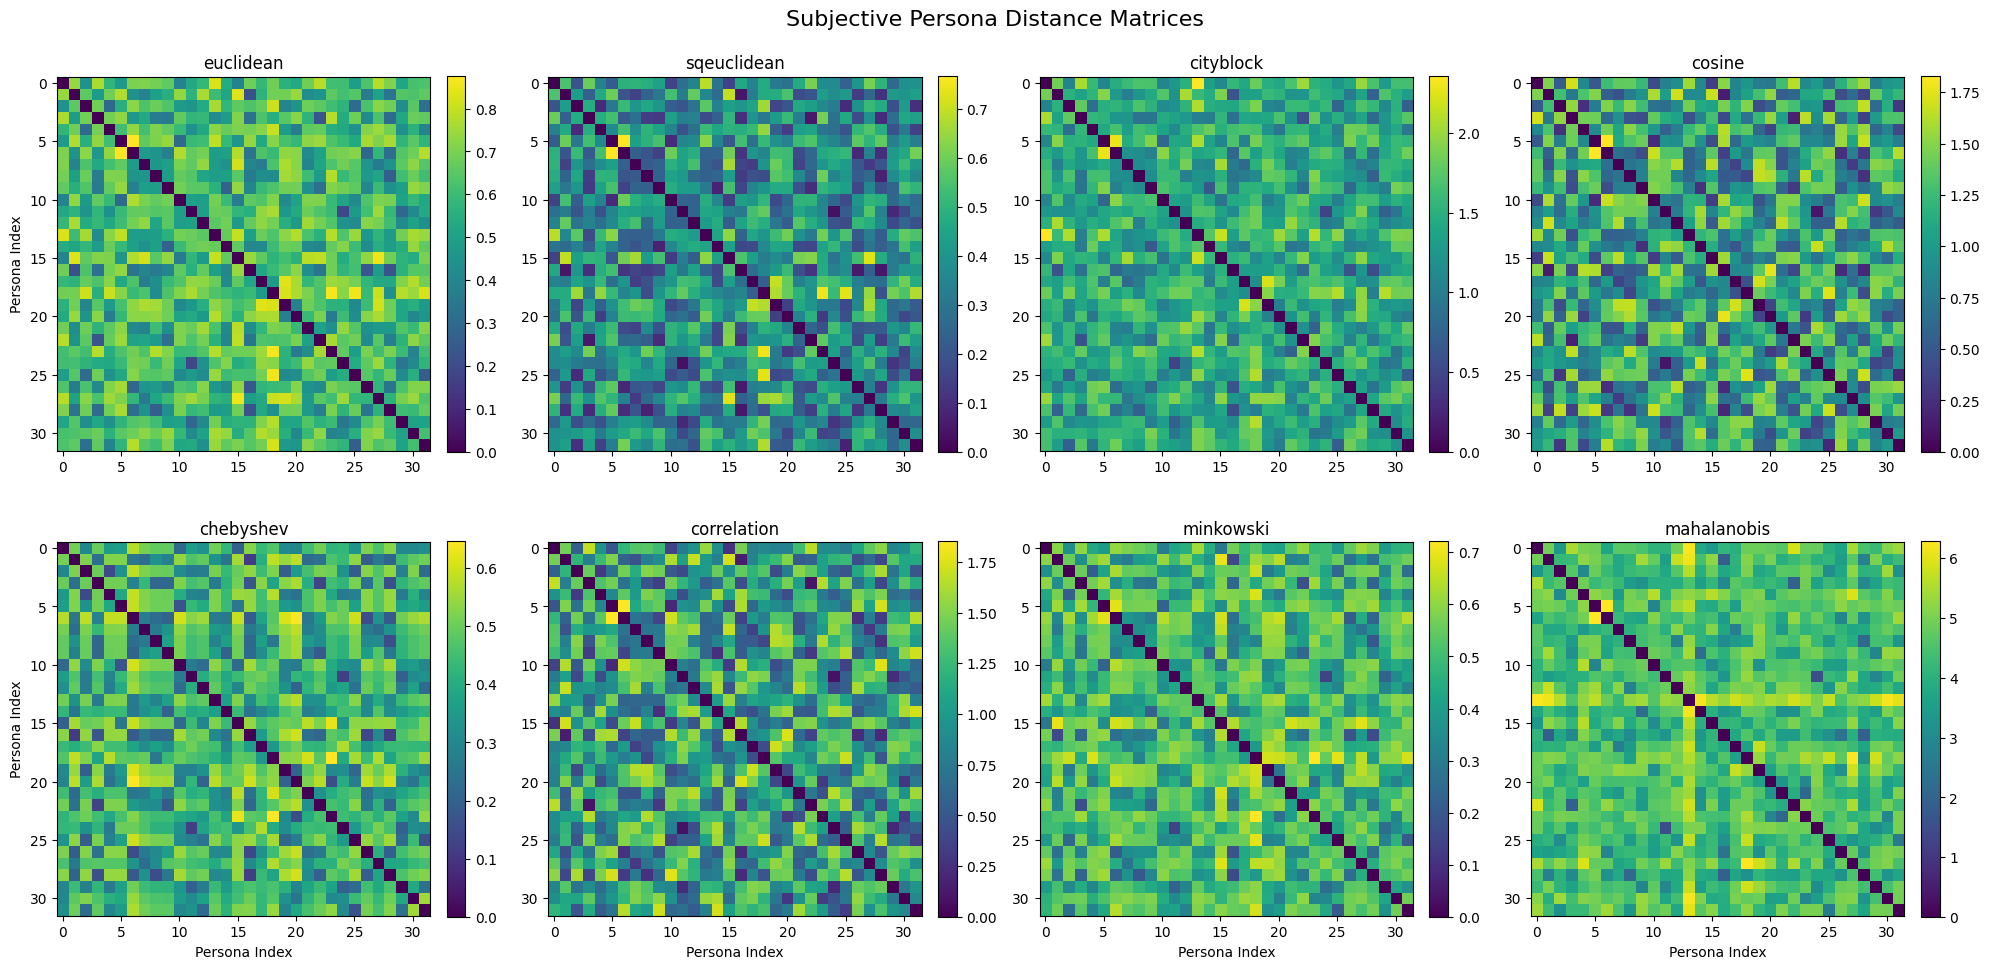

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, (metric, matrix) in enumerate(matrices.items()):
    ax = axes[i]

    im = ax.imshow(matrix, cmap='viridis', interpolation='nearest')
    ax.set_title(metric)

    # Show axis labels only on the outer plots
    if i // 4 == 1:
        ax.set_xlabel('Persona Index')

    if i % 4 == 0:
        ax.set_ylabel('Persona Index')

    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('Subjective Persona Distance Matrices', fontsize=16)
plt.tight_layout()
plt.show()